# Congo Basin above-ground biomass with xarray

**Author:** Kisife F Jude  
**Data:** ESA CCI Biomass v7.0, 10 km aggregated product  
**Analysis window:** 8–32°E, 8°S–6°N

This notebook demonstrates a reproducible xarray workflow for regional
above-ground biomass (AGB): remote subsetting, labelled multi-dimensional data,
latitude-aware area weighting, uncertainty visualisation, and tabular export.
The rectangular window is a regional study frame, not an exact basin boundary.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats("svg")
plt.rcParams.update({"figure.dpi": 120, "font.size": 10})

## 1. Open the public dataset and subset with xarray

`load_biomass_subset` reads only the required region through CEDA's public
NetCDF Subset Service, then caches the small subset locally. No login is required.

In [2]:
from congo_forest.biomass import load_biomass_subset, relative_uncertainty, summarize_biomass

ds = load_biomass_subset()
ds

<xarray.Dataset> Size: 5MB
Dimensions:  (time: 18, lat: 140, lon: 240)
Coordinates:
  * time     (time) datetime64[ns] 144B 2005-01-01 2006-01-01 ... 2024-01-01
  * lat      (lat) float64 1kB 5.95 5.85 5.75 5.65 ... -7.65 -7.75 -7.85 -7.95
  * lon      (lon) float64 2kB 8.05 8.15 8.25 8.35 ... 31.65 31.75 31.85 31.95
Data variables:
    agb      (time, lat, lon) float32 2MB ...
    agb_sd   (time, lat, lon) float32 2MB ...
Attributes: (12/46)
    title:                      ESA CCI above-ground biomass product level 4,...
    institution:                GAMMA Remote Sensing
    source:                     ALOS-2 PALSAR-2 FB and WB mosaics, Sentinel-1...
    history:                    AGB estimation with BIOMASAR-L,v202509, AGB e...
    references:                 http://cci.esa.int/biomass
    tracking_id:                1AA9B124-65A9-46A2-88E3-BF7C60E381E7
    ...                         ...
    date_created:               19-Dec-2025 15:33:59
    EPSG:                       4326
    proj4:                      +proj=longlat +datum=WGS84 +no_defs
    source_url:                 https://dap.ceda.ac.uk/thredds/dodsC/neodc/es...
    regional_bounds_wsen:       (8.0, -8.0, 32.0, 6.0)
    processing:                 Spatial subset only; values are unchanged.

The dataset has labelled `time`, `lat`, and `lon` dimensions. `agb` is above-ground
biomass density in Mg ha⁻¹; `agb_sd` is its per-pixel standard deviation. The
10 km product contains 18 annual layers: 2005–2012 and 2015–2024.

In [3]:
latest = ds.sel(time=np.datetime64("2024-01-01"))
uncertainty = relative_uncertainty(ds, 2024)
latest

<xarray.Dataset> Size: 272kB
Dimensions:  (lat: 140, lon: 240)
Coordinates:
  * lat      (lat) float64 1kB 5.95 5.85 5.75 5.65 ... -7.65 -7.75 -7.85 -7.95
  * lon      (lon) float64 2kB 8.05 8.15 8.25 8.35 ... 31.65 31.75 31.85 31.95
    time     datetime64[ns] 8B 2024-01-01
Data variables:
    agb      (lat, lon) float32 134kB ...
    agb_sd   (lat, lon) float32 134kB ...
Attributes: (12/46)
    title:                      ESA CCI above-ground biomass product level 4,...
    institution:                GAMMA Remote Sensing
    source:                     ALOS-2 PALSAR-2 FB and WB mosaics, Sentinel-1...
    history:                    AGB estimation with BIOMASAR-L,v202509, AGB e...
    references:                 http://cci.esa.int/biomass
    tracking_id:                1AA9B124-65A9-46A2-88E3-BF7C60E381E7
    ...                         ...
    date_created:               19-Dec-2025 15:33:59
    EPSG:                       4326
    proj4:                      +proj=longlat +datum=WGS84 +no_defs
    source_url:                 https://dap.ceda.ac.uk/thredds/dodsC/neodc/es...
    regional_bounds_wsen:       (8.0, -8.0, 32.0, 6.0)
    processing:                 Spatial subset only; values are unchanged.

## 2. Area-weighted descriptive summary

Pixel area varies with latitude on a geographic grid. The summary uses spherical
cell areas rather than treating every pixel as having identical area. Regional
stock includes **all mapped woody AGB** in the window; it is not forest-only and
is not converted to carbon.

In [4]:
summary = summarize_biomass(ds, years=(2010, 2020, 2024))
summary.round(3)

,year,area_weighted_mean_agb_mg_ha,regional_agb_stock_pg,high_biomass_area_percent_agb_ge_200,median_relative_uncertainty_percent
0,2010,148.393,61.486,40.104,18.803
1,2020,146.550,60.722,39.246,18.182
2,2024,146.141,60.553,38.998,18.182


## 3. Biomass and uncertainty maps

The same colour scales make the two panels easy to compare. Areas with high AGB
should be interpreted alongside—not independently of—their uncertainty.

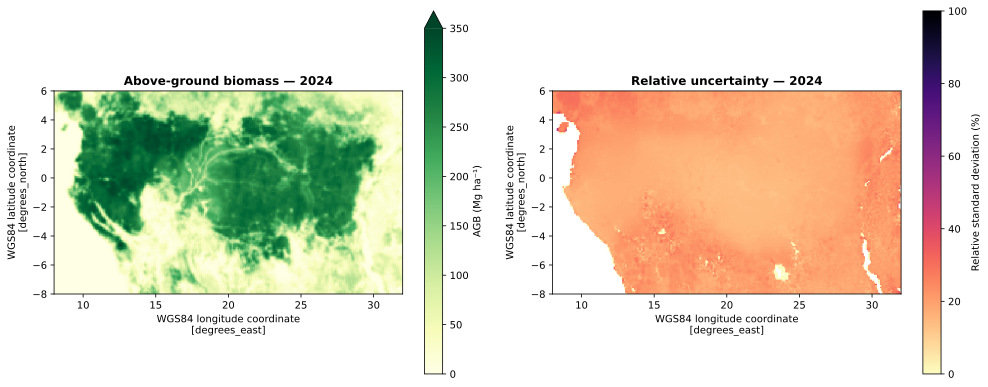

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
latest.agb.plot.imshow(x="lon", y="lat", ax=axes[0], cmap="YlGn", vmin=0, vmax=350,
    cbar_kwargs={"label": "AGB (Mg ha⁻¹)"})
uncertainty.plot.imshow(x="lon", y="lat", ax=axes[1], cmap="magma_r", vmin=0, vmax=100,
    cbar_kwargs={"label": "Relative standard deviation (%)"})
axes[0].set_title("Above-ground biomass — 2024", fontweight="bold")
axes[1].set_title("Relative uncertainty — 2024", fontweight="bold")
for ax in axes:
    ax.set_aspect("equal")
fig.tight_layout()
plt.show()

In [6]:
(ROOT / "outputs" / "tables").mkdir(parents=True, exist_ok=True)
summary.to_csv(ROOT / "outputs" / "tables" / "biomass_regional_summary.csv", index=False)
print("Saved outputs/tables/biomass_regional_summary.csv")

Saved outputs/tables/biomass_regional_summary.csv


## Interpretation and limitations

- The map identifies broad spatial gradients and high-biomass areas at 10 km; it
  does not resolve individual forest stands.
- AGB is an above-ground **biomass** estimate, not a direct carbon or CO₂ estimate.
- The product is not masked to a forest definition. The regional stock therefore
  includes mapped woody biomass outside forests.
- Descriptive differences between years should not automatically be interpreted
  as degradation, deforestation, growth, emissions, or removals. Sensor inputs,
  retrieval methods, and uncertainty matter.
- Use the original 100 m product and an appropriate forest mask for local work.

**Citation:** Santoro, M.; Cartus, O. (2026): ESA Biomass Climate Change
Initiative (Biomass_cci): Global datasets of forest above-ground biomass for
the years 2005–2012 and 2015–2024, v7.0. NERC EDS Centre for Environmental
Data Analysis. https://doi.org/10.5285/6429d1aafe1e43b9b414e4a5a7f8b903